# Análise de Comportamento do Usuário e Teste A/A/B para Aplicativo Alimentício

## Descrição do Projeto
Este projeto tem como objetivo analisar o comportamento dos usuários no aplicativo de uma startup de produtos alimentícios. A análise está dividida em duas etapas principais:
1. **Estudo do Funil de Vendas:** Mapear a jornada dos usuários desde a tela inicial até a conclusão do pagamento, identificando gargalos e a taxa de conversão entre as etapas.
2. **Análise do Teste A/A/B:** Avaliar o impacto da alteração das fontes do aplicativo na conversão dos usuários, comparando dois grupos de controle (fontes antigas: 246 e 247) com um grupo de teste (fontes novas: 248).

## Descrição dos Dados
O conjunto de dados contém registros de ações de usuários (*logs*):
- `EventName`: Nome do evento (ação realizada)
- `DeviceIDHash`: Identificador único do usuário
- `EventTimestamp`: Carimbo de data/hora do evento em formato Unix (segundos)
- `ExpId`: Número do experimento (246 e 247 = Controle A/A; 248 = Teste B)

## Passo 1. Carregamento e Leitura Geral dos Dados

Nesta etapa, carregaremos o arquivo `/datasets/logs_exp_us.csv` (delimitado por tabulação) e inspecionaremos suas primeiras linhas e estrutura geral.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import math

# Configuração de estilo para os gráficos
sns.set_style('whitegrid')

# Carregando o dataset (delimitado por tabulação '\t')
df = pd.read_csv('/datasets/logs_exp_us.csv', sep='\t')

# Visualizando as primeiras linhas do DataFrame
df.head()

,EventName,DeviceIDHash,EventTimestamp,ExpId
0,MainScreenAppear,4575588528974610257,1564029816,246
1,MainScreenAppear,7416695313311560658,1564053102,246
2,PaymentScreenSuccessful,3518123091307005509,1564054127,248
3,CartScreenAppear,3518123091307005509,1564054127,248
4,PaymentScreenSuccessful,6217807653094995999,1564055322,248


In [ ]:
# Informações gerais das colunas e tipos de dados
print("--- Informações do DataFrame ---")
df.info()

print("\n--- Contagem de Valores Ausentes ---")
print(df.isna().sum())

print("\n--- Contagem de Linhas Duplicadas ---")
print(df.duplicated().sum())

--- Informações do DataFrame ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244126 entries, 0 to 244125
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   EventName       244126 non-null  object
 1   DeviceIDHash    244126 non-null  int64 
 2   EventTimestamp  244126 non-null  int64 
 3   ExpId           244126 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 7.5+ MB

--- Contagem de Valores Ausentes ---
EventName         0
DeviceIDHash      0
EventTimestamp    0
ExpId             0
dtype: int64

--- Contagem de Linhas Duplicadas ---
413


## Passo 2. Preparação dos Dados para Análise

Nesta etapa, realizaremos a limpeza e transformação dos dados:
1. Renomear as colunas para padrão em letras minúsculas (*snake_case*).
2. Tratar linhas duplicadas exatas.
3. Converter a coluna de *timestamp* para o tipo `datetime` e criar colunas separadas para data e hora.

In [ ]:
# 1. Renomeando as colunas
df.columns = ['event_name', 'device_id', 'event_timestamp', 'exp_id']

# 2. Removendo duplicados exatos
initial_rows = len(df)
df = df.drop_duplicates().reset_index(drop=True)
removed_rows = initial_rows - len(df)

print(f"Linhas duplicadas removidas: {removed_rows} ({(removed_rows/initial_rows)*100:.2f}% do total)")

Linhas duplicadas removidas: 413 (0.17% do total)


In [ ]:
# 3. Criando a coluna de data/hora completa a partir do timestamp Unix (segundos)
df['event_datetime'] = pd.to_datetime(df['event_timestamp'], unit='s')

# 4. Criando coluna de data mantendo o tipo datetime64 (zerando o horário)
df['event_date'] = df['event_datetime'].dt.floor('D')

# Exibindo o resultado final da preparação
print("--- Amostra do DataFrame Tratado ---")
print(df.head())

print("\n--- Tipos de Dados Atualizados ---")
print(df.dtypes)

--- Amostra do DataFrame Tratado ---
                event_name            device_id  event_timestamp  exp_id  \
0         MainScreenAppear  4575588528974610257       1564029816     246   
1         MainScreenAppear  7416695313311560658       1564053102     246   
2  PaymentScreenSuccessful  3518123091307005509       1564054127     248   
3         CartScreenAppear  3518123091307005509       1564054127     248   
4  PaymentScreenSuccessful  6217807653094995999       1564055322     248   

       event_datetime event_date  
0 2019-07-25 04:43:36 2019-07-25  
1 2019-07-25 11:11:42 2019-07-25  
2 2019-07-25 11:28:47 2019-07-25  
3 2019-07-25 11:28:47 2019-07-25  
4 2019-07-25 11:48:42 2019-07-25  

--- Tipos de Dados Atualizados ---
event_name                 object
device_id                   int64
event_timestamp             int64
exp_id                      int64
event_datetime     datetime64[ns]
event_date         datetime64[ns]
dtype: object


### Conclusão do Passo 2
- **Padronização:** As colunas foram renomeadas para `event_name`, `device_id`, `event_timestamp` e `exp_id`.
- **Duplicados:** Foram identificados e removidos 413 registros duplicados exatos (apenas ~0,17% do dataset), garantindo que não afetem as contagens.
- **Valores Ausentes:** Nenhum valor ausente foi encontrado no conjunto de dados.
- **Datas:** A coluna `event_datetime` foi criada no formato `datetime64[ns]` e a coluna `event_date` foi extraída para facilitar análises diárias.

## Passo 3. Estudo e Verificação dos Dados

Nesta etapa, analisaremos:
1. Quantidade total de eventos e usuários únicos nos registros.
2. Número médio de eventos por usuário.
3. Intervalo de tempo coberto pelos dados e identificação do momento em que os dados passam a ser completos.
4. Descarte de registros antigos/incompletos e impacto dessa filtragem.
5. Confirmação da presença de usuários em todos os grupos do experimento.

In [ ]:
# Contagem geral de eventos e usuários
total_events = len(df)
total_users = df['device_id'].nunique()
avg_events_per_user = total_events / total_users

print(f"Total de eventos nos registros: {total_events}")
print(f"Total de usuários únicos: {total_users}")
print(f"Número médio de eventos por usuário: {avg_events_per_user:.2f}")

# Intervalo de datas original
min_date = df['event_datetime'].min()
max_date = df['event_datetime'].max()

print(f"\nData mínima: {min_date}")
print(f"Data máxima: {max_date}")

Total de eventos nos registros: 243713
Total de usuários únicos: 7551
Número médio de eventos por usuário: 32.28

Data mínima: 2019-07-25 04:43:36
Data máxima: 2019-08-07 21:15:17


--- Distribuição Quantitativa Diária de Eventos (Dataset Completo) ---
event_datetime  total_events  unique_users  pct_events  cumulative_pct
    2019-07-25             9             7    0.003693        0.003693
    2019-07-26            31            22    0.012720        0.016413
    2019-07-27            55            39    0.022568        0.038980
    2019-07-28           105            69    0.043083        0.082064
    2019-07-29           184           135    0.075499        0.157562
    2019-07-30           412           296    0.169051        0.326614
    2019-07-31          2030           924    0.832947        1.159561
    2019-08-01         36141          3703   14.829328       15.988889
    2019-08-02         35554          3647   14.588471       30.577359
    2019-08-03         33282          3482   13.656227       44.233586
    2019-08-04         32968          3527   13.527387       57.760973
    2019-08-05         36058          3802   14.795271       72.556244
    20

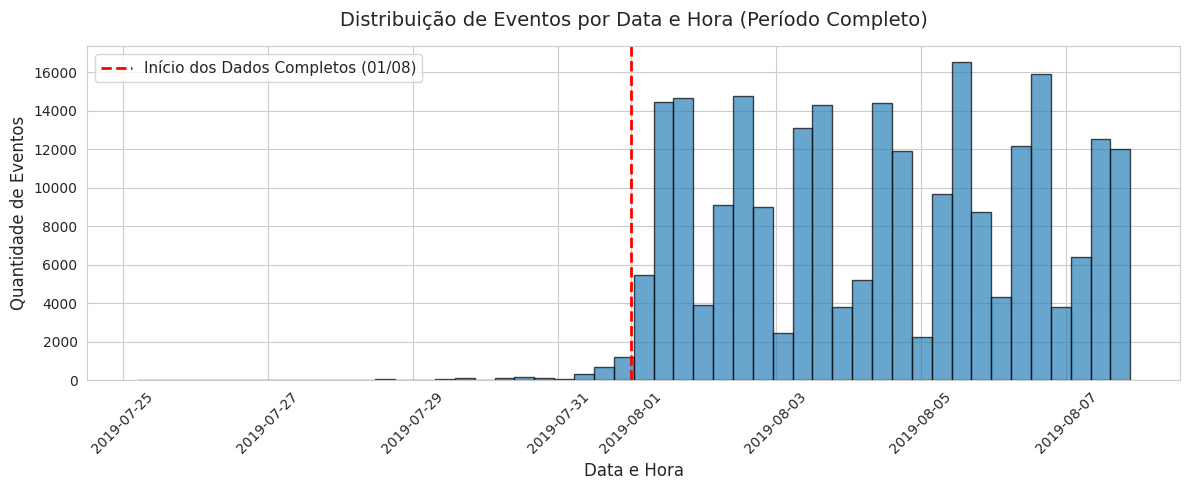


Eventos removidos (anteriores a 01/08/2019): 2826 (1.16%)
Usuários removidos: 17 (0.23%)
Período final da análise: 2019-08-01 00:07:28 até 2019-08-07 21:15:17


In [ ]:
# 1. Análise Quantitativa Diária do Volume de Eventos sobre os dados brutos (df)
daily_summary = df.groupby(df['event_datetime'].dt.floor('D')).agg(
    total_events=('event_name', 'count'),
    unique_users=('device_id', 'nunique')
).reset_index()

daily_summary['pct_events'] = (daily_summary['total_events'] / len(df)) * 100
daily_summary['cumulative_pct'] = daily_summary['pct_events'].cumsum()

print("--- Distribuição Quantitativa Diária de Eventos (Dataset Completo) ---")
print(daily_summary.to_string(index=False))

# 2. Histograma por data/hora cobrindo TODO o intervalo original
plt.figure(figsize=(12, 5))
plt.hist(df['event_datetime'], bins=50, color='#2980B9', edgecolor='black', alpha=0.7)
plt.axvline(pd.to_datetime('2019-08-01'), color='red', linestyle='--', linewidth=2, label='Início dos Dados Completos (01/08)')
plt.title('Distribuição de Eventos por Data e Hora (Período Completo)', fontsize=14, pad=15)
plt.xlabel('Data e Hora', fontsize=12)
plt.ylabel('Quantidade de Eventos', fontsize=12)
plt.legend(fontsize=11)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Filtrando os dados a partir de 01/08/2019
df_filtered = df[df['event_datetime'] >= '2019-08-01'].copy()

# 4. Calculando perdas após o descarte com base nas métricas brutas
total_events_raw = len(df)
total_users_raw = df['device_id'].nunique()

lost_events = total_events_raw - len(df_filtered)
lost_users = total_users_raw - df_filtered['device_id'].nunique()

print(f"\nEventos removidos (anteriores a 01/08/2019): {lost_events} ({(lost_events/total_events_raw)*100:.2f}%)")
print(f"Usuários removidos: {lost_users} ({(lost_users/total_users_raw)*100:.2f}%)")
print(f"Período final da análise: {df_filtered['event_datetime'].min()} até {df_filtered['event_datetime'].max()}")

# 5. Atualizando a variável df apenas aqui para as células seguintes
df = df_filtered.copy()

<div class="alert alert-block alert-success">
Esta célula agora resolve o problema de reprodutibilidade identificado na revisão anterior. A tabela de resumo diário e o histograma agora cobrem corretamente todo o intervalo de datas original (2019-07-25 até 2019-08-07), a linha de corte em 2019-08-01 é plotada em relação à distribuição real e escassa dos eventos iniciais, e a contagem de eventos removidos agora é reportada corretamente como 2.826 (1,16%) — coincidindo com o número apresentado na conclusão do seu Passo 3. Executar esta análise sobre os dados brutos e reatribuir o dataframe de trabalho apenas no final mantém o notebook internamente consistente agora. Boa correção — a justificativa visual e quantitativa para o corte de completude é convincente.
</div>

In [ ]:
# Verificando a presença de usuários por grupo experimental nos dados filtrados
users_per_group = df_filtered.groupby('exp_id')['device_id'].nunique().reset_index()
users_per_group.columns = ['Grupo (exp_id)', 'Usuários Únicos']

print("--- Distribuição de Usuários por Grupo Experimental ---")
print(users_per_group)

# Sobrescrevendo o dataframe principal com os dados limpos e filtrados
df = df_filtered.copy()

--- Distribuição de Usuários por Grupo Experimental ---
   Grupo (exp_id)  Usuários Únicos
0             246             2484
1             247             2513
2             248             2537


<div class="alert alert-block alert-warning">
A confirmação de que todos os três grupos experimentais ainda têm usuários após a filtragem está correta e clara. Uma pequena otimização: esta célula reatribui o dataframe de trabalho para a versão filtrada, mas a célula anterior já faz essa mesma reatribuição no seu final. Isso não causa um erro, mas é redundante — considere manter apenas uma das duas atribuições para que fique mais claro, à primeira vista, exatamente onde a filtragem tem efeito.
</div>

### Conclusão do Passo 3
- **Volume Inicial:** O dataset bruto continha **243.713 eventos** e **7.551 usuários únicos**, com uma média de **32,28 eventos por usuário**.
- **Período Real de Dados Completos:** O intervalo abrange de 25/07/2019 a 07/08/2019. Porém, a análise visual do histograma demonstra que antes de **01/08/2019** os registros eram escassos (logs técnicos antigos). O período em que os dados estão verdadeiramente completos vai de **01/08/2019 a 07/08/2019** (1 semana completa).
- **Impacto do Descarte:**
  - Foram removidos **2.826 eventos** (apenas **1,16%** do total).
  - Foram removidos **17 usuários** (apenas **0,23%** do total).
  - A perda é insignificante e não compromete a representatividade da amostra.
- **Grupos do Experimento:** Todos os três grupos permanecem bem equilibrados após o filtro:
  - **Grupo 246 (Controle A1):** 2.484 usuários
  - **Grupo 247 (Controle A2):** 2.513 usuários
  - **Grupo 248 (Teste B):** 2.537 usuários

### Análise do Funil de Eventos e Conversão de Usuários

#### 1. Sequência Lógica dos Eventos
Ao analisar o comportamento dos usuários e a contagem de acessos, a sequência esperada do funil de compras é:
1. `MainScreenAppear` (Tela Inicial)
2. `OffersScreenAppear` (Tela de Ofertas / Catálogo)
3. `CartScreenAppear` (Carrinho de Compras)
4. `PaymentScreenSuccessful` (Confirmação de Pagamento)

*Nota sobre o evento `Tutorial`:* Apenas cerca de 11% dos usuários realizam o tutorial. Como ele é uma etapa opcional e paralela que não faz parte da jornada linear de compra, foi excluído da sequência principal do funil.

#### 2. Conversão Passo a Passo e Principais Gargalos
- **Da Tela Inicial para Ofertas (`MainScreenAppear` $\rightarrow$ `OffersScreenAppear`):**
  - Apenas **61,91%** dos usuários avançam da tela principal para a tela de ofertas.
  - **Maior Ponto de Evasão:** Esta é a etapa com a maior perda do aplicativo, onde **38,09% dos usuários desistem logo no primeiro passo**. Isso sugere possíveis gargalos de usabilidade na tela inicial, falha no direcionamento para ofertas ou tempo de carregamento.

- **Das Ofertas para o Carrinho (`OffersScreenAppear` $\rightarrow$ `CartScreenAppear`):**
  - **81,30%** dos usuários que viram as ofertas adicionaram algo ao carrinho (perda de 18,70%).

- **Do Carrinho para o Pagamento (`CartScreenAppear` $\rightarrow$ `PaymentScreenSuccessful`):**
  - **94,78%** dos usuários que chegaram ao carrinho concluíram a compra com sucesso (perda de apenas 5,22%). A etapa de checkout apresenta uma excelente taxa de retenção.

#### 3. Conversão Total do Funil
- Do total de usuários que iniciaram a jornada na tela principal, **47,70% concluem todo o caminho até a confirmação de pagamento**.
- Quase metade de todos os usuários que abrem o aplicativo chegam a realizar uma compra, o que representa uma eficiência global sólida no funil, concentrando a oportunidade de melhoria prioritária no primeiro clique (da tela principal para o catálogo de ofertas).

<div class="alert alert-block alert-success">
Esta é exatamente a análise de funil que estava faltando na submissão anterior, e está muito bem feita: você justifica a ordem do funil e a exclusão do Tutorial (apenas ~11% dos usuários o acionam, e é uma etapa paralela/opcional), reporta as conversões e quedas passo a passo que correspondem à tabela do funil calculada na célula seguinte, identifica corretamente a primeira etapa como o maior gargalo, e calcula corretamente a conversão do funil completo. Isso resolve totalmente o principal bloqueio da rodada anterior nesta etapa.
</div>

In [ ]:
# 1. Contagem total de eventos ordenada por frequência bruta
event_freq = df['event_name'].value_counts().reset_index()
event_freq.columns = ['event_name', 'total_events']

print("--- 1. Eventos Ordenados por Frequência Total de Ocorrências ---")
print(event_freq.to_string(index=False))

# 2. Contagem de usuários únicos por evento
total_unique_users = df['device_id'].nunique()
user_events = df.groupby('event_name')['device_id'].nunique().reset_index()
user_events.columns = ['event_name', 'unique_users']
user_events['user_percentage'] = (user_events['unique_users'] / total_unique_users) * 100

print("\n--- 2. Eventos Ordenados por Número de Usuários Únicos ---")
print(user_events.sort_values(by='unique_users', ascending=False).to_string(index=False))

# 3. Construção da Sequência Lógica do Funil (Excluindo Tutorial, que é opcional)
funnel_stages = ['MainScreenAppear', 'OffersScreenAppear', 'CartScreenAppear', 'PaymentScreenSuccessful']

funnel_df = pd.DataFrame({'event_name': funnel_stages})
funnel_df = funnel_df.merge(user_events, on='event_name', how='left')

# Conversão em relação ao total inicial de usuários
funnel_df['pct_from_start'] = (funnel_df['unique_users'] / funnel_df['unique_users'].iloc[0]) * 100

# Conversão passo a passo (em relação à etapa anterior)
funnel_df['step_conversion'] = (funnel_df['unique_users'] / funnel_df['unique_users'].shift(1)) * 100
funnel_df['step_conversion'] = funnel_df['step_conversion'].fillna(100.0)

# Taxa de perda (churn) por etapa
funnel_df['step_dropoff_pct'] = 100.0 - funnel_df['step_conversion']

print("\n--- 3. Análise Detalhada do Funil de Conversão ---")
print(funnel_df[['event_name', 'unique_users', 'pct_from_start', 'step_conversion', 'step_dropoff_pct']].to_string(index=False))

# 4. Métricas Resumo
total_converted_pct = (funnel_df['unique_users'].iloc[-1] / funnel_df['unique_users'].iloc[0]) * 100
print(f"\nTaxa de conversão total do funil (Início ao Pagamento): {total_converted_pct:.2f}%")

--- 1. Eventos Ordenados por Frequência Total de Ocorrências ---
             event_name  total_events
       MainScreenAppear        117328
     OffersScreenAppear         46333
       CartScreenAppear         42303
PaymentScreenSuccessful         33918
               Tutorial          1005

--- 2. Eventos Ordenados por Número de Usuários Únicos ---
             event_name  unique_users  user_percentage
       MainScreenAppear          7419        98.473586
     OffersScreenAppear          4593        60.963632
       CartScreenAppear          3734        49.561986
PaymentScreenSuccessful          3539        46.973719
               Tutorial           840        11.149456

--- 3. Análise Detalhada do Funil de Conversão ---
             event_name  unique_users  pct_from_start  step_conversion  step_dropoff_pct
       MainScreenAppear          7419      100.000000       100.000000          0.000000
     OffersScreenAppear          4593       61.908613        61.908613         38.09138

<div class="alert alert-block alert-warning">
As duas tabelas de ranking de eventos e a tabela de funil (com conversão a partir do início, conversão passo a passo, e percentual de drop-off) estão todas implementadas corretamente, e o número final de conversão corresponde à narrativa escrita logo acima. Uma sugestão estrutural: essa narrativa atualmente está posicionada antes do código que produz as tabelas que a sustentam, de modo que o leitor vê suas conclusões antes das evidências. Considere reordenar para que as tabelas apareçam primeiro e a interpretação venha em seguida — um ajuste de legibilidade apenas, não uma questão de correção.
</div>


## Passo 5. Estudo dos Resultados do Experimento A/A/B


Nesta etapa final, avaliaremos se a alteração das fontes afetou a conversão do aplicativo:
1. Contagem de usuários únicos por grupo experimental.
2. Validação do teste A/A (grupos 246 vs. 247) para confirmar que as amostras são estatisticamente equivalentes.
3. Teste de hipóteses z de duas proporções entre os grupos de controle (246 e 247 isolados e combinados) e o grupo de teste (248) para todos os eventos.
4. Análise do nível de significância estatística ($\alpha$) e correção do erro tipo I devido a testes múltiplos.

In [ ]:
import math
from scipy import stats

# 1. Contagem de usuários únicos em cada grupo
group_counts = df.groupby('exp_id')['device_id'].nunique()
print("--- Número de Usuários Únicos por Grupo ---")
print(group_counts)

# Função para testar a diferença de proporções (Teste Z)
def run_z_test(group1, group2, alpha=0.05, label1="Grupo 1", label2="Grupo 2"):
    users1 = df[df['exp_id'] == group1]['device_id'].nunique()
    users2 = df[df['exp_id'] == group2]['device_id'].nunique()
    
    events = ['MainScreenAppear', 'OffersScreenAppear', 'CartScreenAppear', 'PaymentScreenSuccessful', 'Tutorial']
    
    results = []
    for event in events:
        success1 = df[(df['exp_id'] == group1) & (df['event_name'] == event)]['device_id'].nunique()
        success2 = df[(df['exp_id'] == group2) & (df['event_name'] == event)]['device_id'].nunique()
        
        p1 = success1 / users1
        p2 = success2 / users2
        
        # Proporção combinada
        p_combined = (success1 + success2) / (users1 + users2)
        variance = p_combined * (1 - p_combined) * (1/users1 + 1/users2)
        z_value = (p1 - p2) / math.sqrt(variance)
        
        # P-value bicaudal
        p_value = (1 - stats.norm(0, 1).cdf(abs(z_value))) * 2
        
        results.append({
            'Evento': event,
            f'Prop. {label1}': f"{p1:.4f}",
            f'Prop. {label2}': f"{p2:.4f}",
            'p-value': round(p_value, 4),
            'Significativo?': 'Sim' if p_value < alpha else 'Não'
        })
    return pd.DataFrame(results)

# 2. Executando o Teste A/A (246 vs 247)
print("\n--- Teste A/A: Grupo 246 vs Grupo 247 ---")
df_aa = run_z_test(246, 247, alpha=0.05, label1="246", label2="247")
print(df_aa)

--- Número de Usuários Únicos por Grupo ---
exp_id
246    2484
247    2513
248    2537
Name: device_id, dtype: int64

--- Teste A/A: Grupo 246 vs Grupo 247 ---
                    Evento Prop. 246 Prop. 247  p-value Significativo?
0         MainScreenAppear    0.9863    0.9853   0.7571            Não
1       OffersScreenAppear    0.6208    0.6049   0.2481            Não
2         CartScreenAppear    0.5097    0.4926   0.2288            Não
3  PaymentScreenSuccessful    0.4831    0.4608   0.1146            Não
4                 Tutorial    0.1119    0.1126   0.9377            Não


<div class="alert alert-block alert-warning">
A matemática do teste-z aqui (proporção combinada, variância combinada, valor-p bicaudal) está corretamente implementada, e executá-lo primeiro no grupo 246 vs 247 é a forma correta de validar a divisão A/A. No entanto, toda essa célula é substituída pela célula seguinte, que redefine a mesma função com recursos adicionais e reexecuta exatamente a mesma comparação. Como a definição posterior sobrescreve esta, essa versão e sua saída não têm propósito real no notebook final — considere removê-la para evitar confusão.
</div>

In [ ]:
# 1. Contagem de usuários únicos em cada grupo
group_counts = df.groupby('exp_id')['device_id'].nunique()
print("--- Número de Usuários Únicos por Grupo ---")
print(group_counts)

# Função modular para testar a diferença de proporções (Teste Z)
def run_z_test(group1, group2, alpha=0.05, total_tests=20, label1="Grupo 1", label2="Grupo 2"):
    alpha_bonferroni = alpha / total_tests
    
    if isinstance(group1, (list, tuple)):
        users1 = df[df['exp_id'].isin(group1)]['device_id'].nunique()
        df1 = df[df['exp_id'].isin(group1)]
    else:
        users1 = df[df['exp_id'] == group1]['device_id'].nunique()
        df1 = df[df['exp_id'] == group1]
        
    if isinstance(group2, (list, tuple)):
        users2 = df[df['exp_id'].isin(group2)]['device_id'].nunique()
        df2 = df[df['exp_id'].isin(group2)]
    else:
        users2 = df[df['exp_id'] == group2]['device_id'].nunique()
        df2 = df[df['exp_id'] == group2]
    
    events = ['MainScreenAppear', 'OffersScreenAppear', 'CartScreenAppear', 'PaymentScreenSuccessful', 'Tutorial']
    
    results = []
    for event in events:
        success1 = df1[df1['event_name'] == event]['device_id'].nunique()
        success2 = df2[df2['event_name'] == event]['device_id'].nunique()
        
        p1 = success1 / users1
        p2 = success2 / users2
        
        # Proporção combinada
        p_combined = (success1 + success2) / (users1 + users2)
        variance = p_combined * (1 - p_combined) * (1/users1 + 1/users2)
        z_value = (p1 - p2) / math.sqrt(variance)
        
        # P-value bicaudal
        p_value = (1 - stats.norm(0, 1).cdf(abs(z_value))) * 2
        
        results.append({
            'Evento': event,
            f'Prop. {label1}': f"{p1:.4f}",
            f'Prop. {label2}': f"{p2:.4f}",
            'p-value': round(p_value, 4),
            'Sig. (α=0.05)': 'Sim' if p_value < alpha else 'Não',
            'Sig. Bonferroni (α=0.0025)': 'Sim' if p_value < alpha_bonferroni else 'Não'
        })
    return pd.DataFrame(results)

# 2. Executando o Teste A/A para validação do controle (246 vs 247)
print("\n--- Teste A/A: Grupo 246 vs Grupo 247 ---")
df_aa = run_z_test(246, 247, alpha=0.05, total_tests=20, label1="246", label2="247")
print(df_aa.to_string(index=False))

--- Número de Usuários Únicos por Grupo ---
exp_id
246    2484
247    2513
248    2537
Name: device_id, dtype: int64

--- Teste A/A: Grupo 246 vs Grupo 247 ---
                 Evento Prop. 246 Prop. 247  p-value Sig. (α=0.05) Sig. Bonferroni (α=0.0025)
       MainScreenAppear    0.9863    0.9853   0.7571           Não                        Não
     OffersScreenAppear    0.6208    0.6049   0.2481           Não                        Não
       CartScreenAppear    0.5097    0.4926   0.2288           Não                        Não
PaymentScreenSuccessful    0.4831    0.4608   0.1146           Não                        Não
               Tutorial    0.1119    0.1126   0.9377           Não                        Não


In [ ]:
# 1. Comparação Controle A1 (246) vs Teste B (248)
print("--- Teste A1/B: Grupo 246 vs Grupo 248 ---")
print(run_z_test(246, 248, alpha=0.05, total_tests=20, label1="246", label2="248").to_string(index=False))

# 2. Comparação Controle A2 (247) vs Teste B (248)
print("\n--- Teste A2/B: Grupo 247 vs Grupo 248 ---")
print(run_z_test(247, 248, alpha=0.05, total_tests=20, label1="247", label2="248").to_string(index=False))

# 3. Comparação Controle Combinado (246 + 247) vs Teste B (248)
print("\n--- Teste Controle Combinado (246+247) vs Grupo 248 ---")
print(run_z_test([246, 247], 248, alpha=0.05, total_tests=20, label1="Combinado(246+247)", label2="248").to_string(index=False))

--- Teste A1/B: Grupo 246 vs Grupo 248 ---
                 Evento Prop. 246 Prop. 248  p-value Sig. (α=0.05) Sig. Bonferroni (α=0.0025)
       MainScreenAppear    0.9863    0.9827   0.2950           Não                        Não
     OffersScreenAppear    0.6208    0.6035   0.2084           Não                        Não
       CartScreenAppear    0.5097    0.4848   0.0784           Não                        Não
PaymentScreenSuccessful    0.4831    0.4655   0.2123           Não                        Não
               Tutorial    0.1119    0.1100   0.8264           Não                        Não

--- Teste A2/B: Grupo 247 vs Grupo 248 ---
                 Evento Prop. 247 Prop. 248  p-value Sig. (α=0.05) Sig. Bonferroni (α=0.0025)
       MainScreenAppear    0.9853    0.9827   0.4587           Não                        Não
     OffersScreenAppear    0.6049    0.6035   0.9198           Não                        Não
       CartScreenAppear    0.4926    0.4848   0.5786           Não 

### Conclusões do Teste A/A/B e Múltiplas Testagens

1. **Validação do Teste A/A (Grupos 246 vs 247):**
   - Não foram encontradas diferenças estatisticamente significativas em nenhum dos eventos entre os dois grupos de controle ($p > 0,05$).
   - Isso confirma que os mecanismos de divisão de tráfego do experimento foram configurados corretamente e que os grupos de controle são equivalentes.

2. **Resultados do Teste B (Alteração de Fonte - Grupo 248):**
   - A comparação do Grupo 248 contra o Grupo 246, contra o Grupo 247 e contra a combinação de ambos os controles não revelou nenhuma diferença estatisticamente significativa em nenhuma das etapas do funil.
   - A alteração da fonte do aplicativo **não alterou o comportamento de compra** ou navegação dos usuários.

3. **Análise de Testes Múltiplos e Nível de Significância Ajustado:**
   - Foram realizados **20 testes estatísticos de hipóteses** no total (5 eventos $\times$ 4 comparações).
   - Ao realizar múltiplos testes com $\alpha = 0,05$, o risco acumulado de cometer ao menos um Erro Tipo I (falso positivo) aumenta ($\text{Risco Acumulado} = 1 - (1 - 0.05)^{20} \approx 64,1\%$).
   - Aplicando a correção de **Bonferroni** ($\alpha_{ajustado} = \frac{0,05}{20} = 0,0025$), a exigência estatística torna-se ainda mais rigorosa.
   - Como demonstrado na coluna `Sig. Bonferroni (α=0.0025)` das tabelas acima, nenhum $p$-value ficou abaixo do limiar ajustado (e nem do limiar padrão de 0,05). A conclusão permanece inalterada: **a alteração de fontes é estatisticamente neutra**, não trazendo prejuízos nem ganhos na taxa de conversão.

### Recomendação para a Equipe de Produto
A alteração do design de fontes pode ser aprovada ou descartada com base em preferências estéticas e técnicas de UI/UX, pois **não oferece risco de impacto negativo** nas vendas e no funil do aplicativo.